In [1]:
import pandas as pd

In [2]:
df = pd.read_excel("Online Retail.xlsx")

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent.round(2)

InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64

In [6]:
df.duplicated().sum()

5268

In [7]:
df[df.duplicated()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [8]:
df_clean = df.drop_duplicates().copy()

In [9]:
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())

Original rows: 541909
Cleaned rows: 536641
Duplicates remaining: 0


In [10]:
df_clean.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

In [11]:
(df_clean.isnull().sum() / len(df_clean) * 100).round(2)

InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     25.16
Country         0.00
dtype: float64

In [12]:
(df_clean["Quantity"] <= 0).sum()

10587

In [13]:
df_clean[df_clean["Quantity"] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [14]:
df_clean["InvoiceNo"].astype(str).str.startswith("C").sum()

9251

In [15]:
(
    (df_clean["Quantity"] < 0)
    & (df_clean["InvoiceNo"].astype(str).str.startswith("C"))
).sum()

9251

In [16]:
(df_clean["Quantity"] == 0).sum()

0

In [17]:
df_clean[
    (df_clean["Quantity"] < 0)
    & (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom


In [18]:
(df_clean["UnitPrice"] <= 0).sum()

2512

In [19]:
df_clean[df_clean["UnitPrice"] <= 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom


In [20]:
df_clean.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

In [21]:
df_clean["Quantity"].describe()

count    536641.000000
mean          9.620029
std         219.130156
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

In [22]:
df_clean["UnitPrice"].describe()

count    536641.000000
mean          4.632656
std          97.233118
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

In [23]:
df_clean[df_clean["UnitPrice"] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [24]:
(df_clean["UnitPrice"] < 0).sum()

2

In [25]:
(df_clean["UnitPrice"] == 0).sum()

2510

In [26]:
df_clean.loc[
    df_clean["UnitPrice"] == 0,
    ["InvoiceNo", "StockCode", "Description", "Quantity", "CustomerID"]
].head()

,InvoiceNo,StockCode,Description,Quantity,CustomerID
622,536414,22139,NaN,56,NaN
1970,536545,21134,NaN,1,NaN
1971,536546,22145,NaN,1,NaN
1972,536547,37509,NaN,1,NaN
1987,536549,85226A,NaN,1,NaN


In [27]:
print(
    df_clean.loc[
        df_clean["UnitPrice"] == 0,
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "CustomerID", "Country"]
    ].head(10).to_string(index=False)
)

InvoiceNo StockCode Description  Quantity  UnitPrice  CustomerID        Country
   536414     22139         NaN        56        0.0         NaN United Kingdom
   536545     21134         NaN         1        0.0         NaN United Kingdom
   536546     22145         NaN         1        0.0         NaN United Kingdom
   536547     37509         NaN         1        0.0         NaN United Kingdom
   536549    85226A         NaN         1        0.0         NaN United Kingdom
   536550     85044         NaN         1        0.0         NaN United Kingdom
   536552     20950         NaN         1        0.0         NaN United Kingdom
   536553     37461         NaN         3        0.0         NaN United Kingdom
   536554     84670         NaN        23        0.0         NaN United Kingdom
   536589     21777         NaN       -10        0.0         NaN United Kingdom


In [28]:
(
    (df_clean["UnitPrice"] == 0)
    & (df_clean["Description"].isnull())
).sum()

1454

In [29]:
df_clean.loc[
    (df_clean["UnitPrice"] == 0)
    & (df_clean["Description"].notnull()),
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
].head(10).to_string(index=False)

'InvoiceNo StockCode                      Description  Quantity  UnitPrice\n   536941     22734                           amazon        20        0.0\n   536942     22139                           amazon        15        0.0\n   537032     21275                                ?       -30        0.0\n   537197     22841     ROUND CAKE TIN VINTAGE GREEN         1        0.0\n   537425    84968F                            check       -20        0.0\n   537426    84968E                            check       -35        0.0\n   537432    35833G                          damages       -43        0.0\n   537534     85064     CREAM SWEETHEART LETTER RACK         1        0.0\n   537534     84832 ZINC WILLIE WINKIE  CANDLE STICK         1        0.0\n   537534     84692      BOX OF 24 COCKTAIL PARASOLS         2        0.0'

In [30]:
(
    (df_clean["UnitPrice"] == 0)
    & (df_clean["Description"].notnull())
).sum()

1056

In [31]:
df_clean["Description"].value_counts().head(20)

Description
WHITE HANGING HEART T-LIGHT HOLDER    2357
REGENCY CAKESTAND 3 TIER              2189
JUMBO BAG RED RETROSPOT               2156
PARTY BUNTING                         1720
LUNCH BAG RED RETROSPOT               1625
ASSORTED COLOUR BIRD ORNAMENT         1488
SET OF 3 CAKE TINS PANTRY DESIGN      1465
PACK OF 72 RETROSPOT CAKE CASES       1367
LUNCH BAG  BLACK SKULL.               1323
NATURAL SLATE HEART CHALKBOARD        1272
POSTAGE                               1252
JUMBO BAG PINK POLKADOT               1245
HEART OF WICKER SMALL                 1230
JAM MAKING SET WITH JARS              1221
JUMBO STORAGE BAG SUKI                1211
PAPER CHAIN KIT 50'S CHRISTMAS        1194
JUMBO SHOPPER VINTAGE RED PAISLEY     1192
LUNCH BAG CARS BLUE                   1185
JAM MAKING SET PRINTED                1177
LUNCH BAG SPACEBOY DESIGN             1177
Name: count, dtype: int64

In [32]:
df_clean.loc[
    df_clean["Description"].str.contains(
        r"amazon|check|damages|\?",
        case=False,
        na=False
    ),
    "Description"
].value_counts().head(20)

Description
check                              159
BROWN CHECK CAT DOORSTOP           139
SUNSET CHECK HAMMOCK                62
?                                   47
damages                             45
PAIR PADDED HANGERS PINK CHECK      43
AMAZON FEE                          34
amazon                               8
??                                   7
Amazon                               7
BLUE CHECK BAG W HANDLE 34X20CM      6
damages?                             5
AMAZON                               3
BLUE CRUSOE CHECK LAMPSHADE          3
CHECK                                3
damages wax                          2
???missing                           2
?missing                             2
stock check                          2
???                                  1
Name: count, dtype: int64

In [33]:
suspicious_descriptions = [
    "check",
    "damages",
    "?",
    "??",
    "???",
    "???missing",
    "?missing",
    "damages?",
    "damages wax",
    "stock check",
    "amazon"
]

df_clean.loc[
    df_clean["Description"].str.strip().str.lower().isin(suspicious_descriptions),
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "Country"]
].head(20).to_string(index=False)

'InvoiceNo StockCode Description  Quantity  UnitPrice  CustomerID        Country\n   536941     22734      amazon        20        0.0         NaN United Kingdom\n   536942     22139      amazon        15        0.0         NaN United Kingdom\n   537032     21275           ?       -30        0.0         NaN United Kingdom\n   537425    84968F       check       -20        0.0         NaN United Kingdom\n   537426    84968E       check       -35        0.0         NaN United Kingdom\n   537432    35833G     damages       -43        0.0         NaN United Kingdom\n   537639     22734      amazon        30        0.0         NaN United Kingdom\n   538090     20956           ?      -723        0.0         NaN United Kingdom\n   538348     22734      amazon        30        0.0         NaN United Kingdom\n   539494     21479           ?       752        0.0         NaN United Kingdom\n   540100     22837           ?      -106        0.0         NaN United Kingdom\n   540558     21258        

In [34]:
suspicious_descriptions = [
    "check", "damages", "?", "??", "???",
    "???missing", "?missing", "damages?",
    "damages wax", "stock check", "amazon"
]

mask = df_clean["Description"].str.strip().str.lower().isin(
    suspicious_descriptions
)

print("Suspicious rows:", mask.sum())
print("Zero-price rows:", (df_clean.loc[mask, "UnitPrice"] == 0).sum())
print("Negative-quantity rows:", (df_clean.loc[mask, "Quantity"] < 0).sum())
print("Missing-customer rows:", df_clean.loc[mask, "CustomerID"].isna().sum())

Suspicious rows: 294
Zero-price rows: 294
Negative-quantity rows: 231
Missing-customer rows: 294


In [35]:
total_rows = len(df_clean)
suspicious_count = mask.sum()

suspicious_percentage = suspicious_count / total_rows * 100

print(f"Total rows: {total_rows:,}")
print(f"Suspicious rows: {suspicious_count:,}")
print(f"Percentage: {suspicious_percentage:.2f}%")

Total rows: 536,641
Suspicious rows: 294
Percentage: 0.05%


In [36]:
df_clean.loc[
    df_clean["UnitPrice"] < 0,
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]
].to_string(index=False)

'InvoiceNo StockCode     Description  Quantity  UnitPrice  CustomerID        Country\n  A563186         B Adjust bad debt         1  -11062.06         NaN United Kingdom\n  A563187         B Adjust bad debt         1  -11062.06         NaN United Kingdom'

In [37]:
df_clean.loc[
    df_clean["Quantity"] < 0,
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
].head(15).to_string(index=False)

'InvoiceNo StockCode                         Description  Quantity  UnitPrice\n  C536379         D                            Discount        -1      27.50\n  C536383    35004C     SET OF 3 COLOURED  FLYING DUCKS        -1       4.65\n  C536391     22556      PLASTERS IN TIN CIRCUS PARADE        -12       1.65\n  C536391     21984    PACK OF 12 PINK PAISLEY TISSUES        -24       0.29\n  C536391     21983    PACK OF 12 BLUE PAISLEY TISSUES        -24       0.29\n  C536391     21980   PACK OF 12 RED RETROSPOT TISSUES        -24       0.29\n  C536391     21484         CHICK GREY HOT WATER BOTTLE       -12       3.45\n  C536391     22557    PLASTERS IN TIN VINTAGE PAISLEY        -12       1.65\n  C536391     22553              PLASTERS IN TIN SKULLS       -24       1.65\n  C536506     22960            JAM MAKING SET WITH JARS        -6       4.25\n  C536543     22632           HAND WARMER RED RETROSPOT        -1       2.10\n  C536543     22355           CHARLOTTE BAG SUKI DESIGN        

In [38]:
negative_quantity = df_clean["Quantity"] < 0

cancelled_invoice = (
    df_clean["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

print("Rows with negative quantity:", negative_quantity.sum())

print(
    "Negative quantity rows with invoice starting C:",
    (negative_quantity & cancelled_invoice).sum()
)

print(
    "Negative quantity rows without invoice starting C:",
    (negative_quantity & ~cancelled_invoice).sum()
)

Rows with negative quantity: 10587
Negative quantity rows with invoice starting C: 9251
Negative quantity rows without invoice starting C: 1336


In [39]:
print("Earliest invoice date:", df_clean["InvoiceDate"].min())
print("Latest invoice date:", df_clean["InvoiceDate"].max())
print("Missing invoice dates:", df_clean["InvoiceDate"].isna().sum())

Earliest invoice date: 2010-12-01 08:26:00
Latest invoice date: 2011-12-09 12:50:00
Missing invoice dates: 0


In [40]:
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Missing CustomerID:", df_clean["CustomerID"].isna().sum())
print("Missing CustomerID (%):",
      round(df_clean["CustomerID"].isna().mean() * 100, 2))

Unique customers: 4372
Missing CustomerID: 135037
Missing CustomerID (%): 25.16


In [41]:
print("Largest quantities:")
print(
    df_clean.loc[
        df_clean["Quantity"].abs().nlargest(5).index,
        ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
    ].to_string(index=False)
)

print("\nLargest unit prices:")
print(
    df_clean.loc[
        df_clean["UnitPrice"].abs().nlargest(5).index,
        ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
    ].to_string(index=False)
)

Largest quantities:
InvoiceNo StockCode                    Description  Quantity  UnitPrice
   581483     23843    PAPER CRAFT , LITTLE BIRDIE     80995       2.08
  C581484     23843    PAPER CRAFT , LITTLE BIRDIE    -80995       2.08
   541431     23166 MEDIUM CERAMIC TOP STORAGE JAR     74215       1.04
  C541433     23166 MEDIUM CERAMIC TOP STORAGE JAR    -74215       1.04
   578841     84826 ASSTD DESIGN 3D PAPER STICKERS     12540       0.00

Largest unit prices:
InvoiceNo StockCode Description  Quantity  UnitPrice
  C556445         M      Manual        -1   38970.00
  C580605 AMAZONFEE  AMAZON FEE        -1   17836.46
  C540117 AMAZONFEE  AMAZON FEE        -1   16888.02
  C540118 AMAZONFEE  AMAZON FEE        -1   16453.71
  C537630 AMAZONFEE  AMAZON FEE        -1   13541.33


In [42]:
print("Duplicate rows remaining:", df_clean.duplicated().sum())

Duplicate rows remaining: 0


In [43]:
text_columns = ["InvoiceNo", "StockCode", "Description", "Country"]

for column in text_columns:
    values = df_clean[column].dropna().astype(str)
    extra_spaces = values.ne(values.str.strip()).sum()
    print(f"{column}: {extra_spaces} values with extra spaces")

InvoiceNo: 0 values with extra spaces
StockCode: 0 values with extra spaces
Description: 112371 values with extra spaces
Country: 0 values with extra spaces


In [44]:
df_clean["Description"] = df_clean["Description"].str.strip()

print(
    "Description values with extra spaces:",
    df_clean["Description"]
    .dropna()
    .ne(df_clean["Description"].dropna().str.strip())
    .sum()
)

Description values with extra spaces: 0


In [45]:
df_clean["Country"].value_counts().head(20)

Country
United Kingdom     490300
Germany              9480
France               8541
EIRE                 8184
Spain                2528
Netherlands          2371
Belgium              2069
Switzerland          1994
Portugal             1510
Australia            1258
Norway               1086
Italy                 803
Channel Islands       757
Finland               695
Cyprus                611
Sweden                461
Unspecified           442
Austria               401
Denmark               389
Japan                 358
Name: count, dtype: int64

In [46]:
print("Unique country values:", df_clean["Country"].nunique())

print("\nAll country names:")
print(sorted(df_clean["Country"].dropna().unique()))

Unique country values: 38

All country names:
['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'Channel Islands', 'Cyprus', 'Czech Republic', 'Denmark', 'EIRE', 'European Community', 'Finland', 'France', 'Germany', 'Greece', 'Hong Kong', 'Iceland', 'Israel', 'Italy', 'Japan', 'Lebanon', 'Lithuania', 'Malta', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'RSA', 'Saudi Arabia', 'Singapore', 'Spain', 'Sweden', 'Switzerland', 'USA', 'United Arab Emirates', 'United Kingdom', 'Unspecified']


In [47]:
print("Missing StockCode:", df_clean["StockCode"].isna().sum())
print("Unique StockCode values:", df_clean["StockCode"].nunique())

print("\nMost frequent StockCodes:")
print(df_clean["StockCode"].value_counts().head(10))

Missing StockCode: 0
Unique StockCode values: 4070

Most frequent StockCodes:
StockCode
85123A    2301
22423     2192
85099B    2156
47566     1720
20725     1626
84879     1489
22720     1469
22197     1468
21212     1367
22383     1328
Name: count, dtype: int64


In [48]:
missing_description = df_clean["Description"].isna()

print("Rows with missing Description:", missing_description.sum())

print("\nMost frequent StockCodes in rows with missing Description:")
print(
    df_clean.loc[missing_description, "StockCode"]
    .value_counts()
    .head(10)
)

Rows with missing Description: 1455

Most frequent StockCodes in rows with missing Description:
StockCode
23084    10
35965    10
22084     9
22451     6
22501     5
21033     5
21784     5
21067     5
23348     5
22866     5
Name: count, dtype: int64


In [49]:
missing_both = (
    df_clean["Description"].isna()
    & df_clean["CustomerID"].isna()
)

print("Missing both Description and CustomerID:", missing_both.sum())

print(
    "Percentage of missing Description rows:",
    round(missing_both.sum() / df_clean["Description"].isna().sum() * 100, 2),
    "%"
)

Missing both Description and CustomerID: 1455
Percentage of missing Description rows: 100.0 %


In [50]:
missing_description_count = df_clean["Description"].isna().sum()

print("Total rows:", len(df_clean))
print("Missing Description:", missing_description_count)
print(
    "Missing Description (%):",
    round(df_clean["Description"].isna().mean() * 100, 2),
    "%"
)

Total rows: 536641
Missing Description: 1455
Missing Description (%): 0.27 %


In [51]:
customer_ids = df_clean["CustomerID"].dropna()

print(
    "CustomerIDs with decimal parts:",
    (customer_ids % 1 != 0).sum()
)

CustomerIDs with decimal parts: 0


In [52]:
df_clean["CustomerID"] = df_clean["CustomerID"].astype("Int64")

print(df_clean["CustomerID"].dtype)
print(df_clean["CustomerID"].head(10))

Int64
0    17850
1    17850
2    17850
3    17850
4    17850
5    17850
6    17850
7    17850
8    17850
9    13047
Name: CustomerID, dtype: Int64


In [53]:
df_clean.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              Int64
Country                object
dtype: object

In [54]:
print("Dataset shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nMissing values per column:")
print(df_clean.isna().sum())

Dataset shape: (536641, 8)
Duplicate rows: 0

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1455
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [55]:
df_clean.to_csv("online_retail_cleaned.csv", index=False)

In [56]:
quality_report = pd.DataFrame({
    "Missing Values": df_clean.isna().sum(),
    "Missing Percentage": (df_clean.isna().mean() * 100).round(2),
    "Data Type": df_clean.dtypes.astype(str)
})

quality_report

,Missing Values,Missing Percentage,Data Type
InvoiceNo,0,0.00,object
StockCode,0,0.00,object
Description,1455,0.27,object
Quantity,0,0.00,int64
InvoiceDate,0,0.00,datetime64[ns]
UnitPrice,0,0.00,float64
CustomerID,135037,25.16,Int64
Country,0,0.00,object


In [57]:
quality_report.to_csv("data_quality_report.csv")

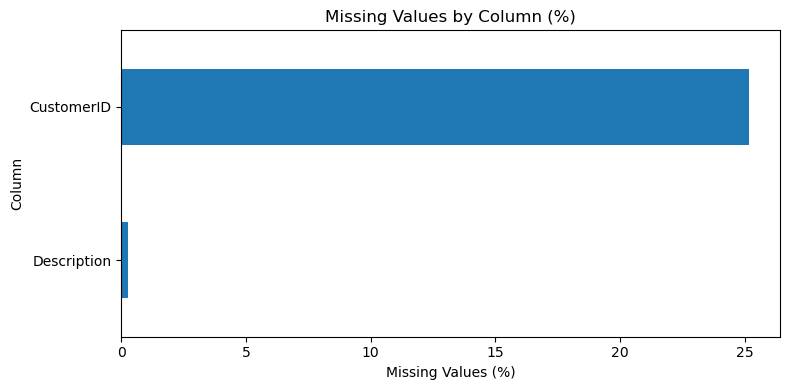

In [58]:
import matplotlib.pyplot as plt

missing_percent = df_clean.isna().mean().mul(100)
missing_percent = missing_percent[missing_percent > 0].sort_values()

plt.figure(figsize=(8, 4))
missing_percent.plot(kind="barh")

plt.title("Missing Values by Column (%)")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")

plt.tight_layout()
plt.show()

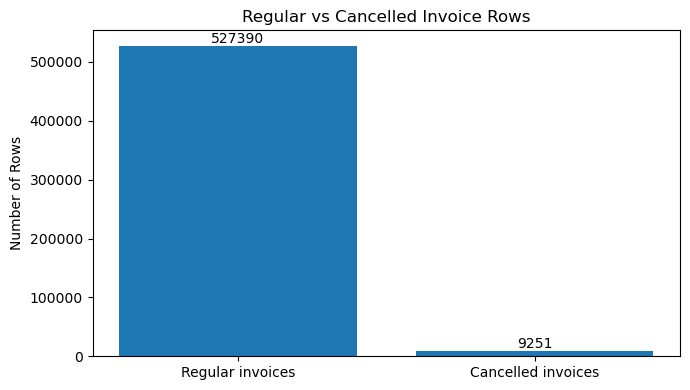

In [59]:
import matplotlib.pyplot as plt

is_cancelled = df_clean["InvoiceNo"].astype(str).str.startswith("C")

invoice_types = [
    "Regular invoices",
    "Cancelled invoices"
]

invoice_counts = [
    (~is_cancelled).sum(),
    is_cancelled.sum()
]

plt.figure(figsize=(7, 4))
bars = plt.bar(invoice_types, invoice_counts)

plt.title("Regular vs Cancelled Invoice Rows")
plt.ylabel("Number of Rows")
plt.bar_label(bars, fmt="%.0f")

plt.tight_layout()
plt.savefig("invoice_types.png", dpi=300, bbox_inches="tight")
plt.show()

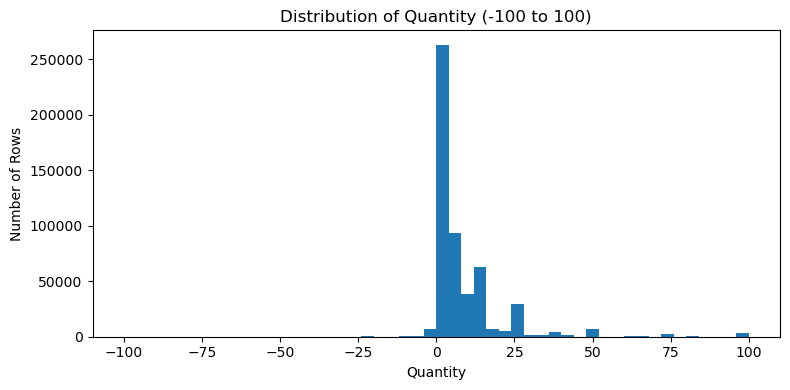

In [60]:
import matplotlib.pyplot as plt

quantity_subset = df_clean.loc[
    df_clean["Quantity"].between(-100, 100),
    "Quantity"
]

plt.figure(figsize=(8, 4))
plt.hist(quantity_subset, bins=50)

plt.title("Distribution of Quantity (-100 to 100)")
plt.xlabel("Quantity")
plt.ylabel("Number of Rows")

plt.tight_layout()
plt.savefig("quantity_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [61]:
import os

for file in os.listdir("."):
    print(file)

.ipynb_checkpoints
data_cleaning.ipynb.ipynb
data_quality_report.csv
data_quality_summary.csv
invoice_types.png
missing_values.png
Online Retail.xlsx
online_retail_cleaned.csv
quantity_distribution.png
README.md.txt


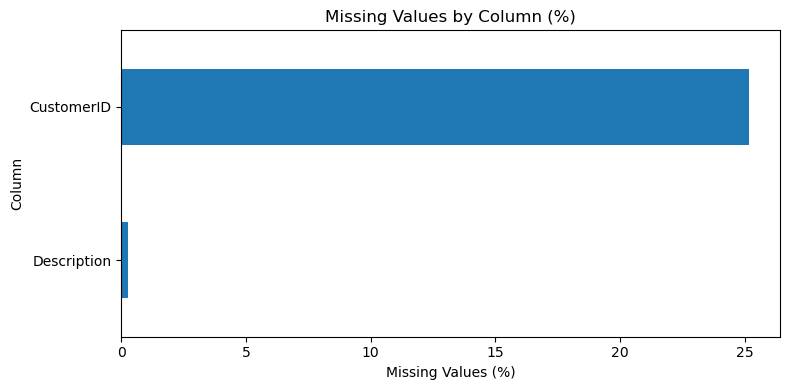

In [62]:
missing_percent = df_clean.isna().mean().mul(100)
missing_percent = missing_percent[missing_percent > 0].sort_values()

plt.figure(figsize=(8, 4))
missing_percent.plot(kind="barh")

plt.title("Missing Values by Column (%)")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")

plt.tight_layout()
plt.savefig("missing_values.png", dpi=300, bbox_inches="tight")
plt.show()

In [63]:
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Duplicate rows:", df_clean.duplicated().sum())

Rows: 536641
Columns: 8
Duplicate rows: 0


In [64]:
print("Zero prices:", (df_clean["UnitPrice"] == 0).sum())
print("Negative prices:", (df_clean["UnitPrice"] < 0).sum())

Zero prices: 2510
Negative prices: 2


In [65]:
df_clean.loc[
    df_clean["UnitPrice"] < 0,
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
299983,A563186,B,Adjust bad debt,1,-11062.06
299984,A563187,B,Adjust bad debt,1,-11062.06


In [66]:
df_clean.loc[
    df_clean["UnitPrice"] == 0,
    "Description"
].value_counts().head(10)

Description
check                     159
?                          47
damages                    45
damaged                    43
found                      25
sold as set on dotcom      20
adjustment                 16
Damaged                    14
Unsaleable, destroyed.      9
thrown away                 9
Name: count, dtype: int64

In [67]:
df_clean.loc[
    df_clean["UnitPrice"] == 0,
    "Quantity"
].describe()

count     2510.000000
mean       -53.529880
std        540.739276
min      -9600.000000
25%        -32.750000
50%         -2.000000
75%          3.000000
max      12540.000000
Name: Quantity, dtype: float64

In [68]:
negative_quantity = df_clean["Quantity"] < 0

print("Negative quantity rows:", negative_quantity.sum())

print(
    "Negative quantity with cancellation invoice:",
    (
        negative_quantity
        & df_clean["InvoiceNo"].astype(str).str.startswith("C")
    ).sum()
)

Negative quantity rows: 10587
Negative quantity with cancellation invoice: 9251


In [69]:
df_clean.loc[
    (df_clean["Quantity"] < 0)
    & ~df_clean["InvoiceNo"].astype(str).str.startswith("C"),
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
].head(10)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
2406,536589,21777,NaN,-10,0.0
4347,536764,84952C,NaN,-38,0.0
7188,536996,22712,NaN,-20,0.0
7189,536997,22028,NaN,-20,0.0
7190,536998,85067,NaN,-6,0.0
7192,537000,21414,NaN,-22,0.0
7193,537001,21653,NaN,-6,0.0
7195,537003,85126,NaN,-2,0.0
7196,537004,21814,NaN,-30,0.0
7197,537005,21692,NaN,-70,0.0


In [70]:
sample = df_clean.loc[
    (df_clean["Quantity"] < 0)
    & ~df_clean["InvoiceNo"].astype(str).str.startswith("C"),
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
].head(3)

print(sample.to_string(index=False))

InvoiceNo StockCode Description  Quantity  UnitPrice
   536589     21777         NaN       -10        0.0
   536764    84952C         NaN       -38        0.0
   536996     22712         NaN       -20        0.0


In [71]:
mask = (
    (df_clean["Quantity"] < 0)
    & (df_clean["UnitPrice"] == 0)
    & (df_clean["Description"].isna())
)

print("Rows matching all three conditions:", mask.sum())

Rows matching all three conditions: 863


In [72]:
print(
    "Percentage of dataset:",
    round(mask.sum() / len(df_clean) * 100, 2),
    "%"
)

Percentage of dataset: 0.16 %


In [73]:
summary = pd.DataFrame({
    "Check": [
        "Duplicate rows",
        "Missing descriptions",
        "Missing customer IDs",
        "Zero unit prices",
        "Negative unit prices",
        "Negative quantities",
        "Negative quantity + zero price + missing description"
    ],
    "Count": [
        df_clean.duplicated().sum(),
        df_clean["Description"].isna().sum(),
        df_clean["CustomerID"].isna().sum(),
        (df_clean["UnitPrice"] == 0).sum(),
        (df_clean["UnitPrice"] < 0).sum(),
        (df_clean["Quantity"] < 0).sum(),
        mask.sum()
    ]
})

summary

,Check,Count
0,Duplicate rows,0
1,Missing descriptions,1455
2,Missing customer IDs,135037
3,Zero unit prices,2510
4,Negative unit prices,2
5,Negative quantities,10587
6,Negative quantity + zero price + missing descr...,863


In [74]:
summary["Percentage"] = (
    summary["Count"] / len(df_clean) * 100
).round(2)

summary

,Check,Count,Percentage
0,Duplicate rows,0,0.00
1,Missing descriptions,1455,0.27
2,Missing customer IDs,135037,25.16
3,Zero unit prices,2510,0.47
4,Negative unit prices,2,0.00
5,Negative quantities,10587,1.97
6,Negative quantity + zero price + missing descr...,863,0.16


In [75]:
summary.to_csv("data_quality_summary.csv", index=False)

In [76]:
df_clean.loc[
    df_clean["CustomerID"].isna(),
    ["InvoiceNo", "Description", "Quantity", "UnitPrice", "Country"]
].head(10)

,InvoiceNo,Description,Quantity,UnitPrice,Country
622,536414,NaN,56,0.00,United Kingdom
1443,536544,DECORATIVE ROSE BATHROOM BOTTLE,1,2.51,United Kingdom
1444,536544,DECORATIVE CATS BATHROOM BOTTLE,2,2.51,United Kingdom
1445,536544,POLKADOT RAIN HAT,4,0.85,United Kingdom
1446,536544,RAIN PONCHO RETROSPOT,2,1.66,United Kingdom
1447,536544,VINTAGE SNAP CARDS,9,1.66,United Kingdom
1448,536544,VINTAGE HEADS AND TAILS CARD GAME,2,2.51,United Kingdom
1449,536544,CHRISTMAS TREE DECORATION WITH BELL,10,0.43,United Kingdom
1450,536544,CHRISTMAS TREE HEART DECORATION,9,0.43,United Kingdom
1451,536544,CHRISTMAS TREE STAR DECORATION,11,0.43,United Kingdom
